In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, SimpleRNN, LSTM
from tensorflow.keras.initializers import GlorotUniform

np.set_printoptions(precision=4)
tf.random.set_seed(42)
np.random.seed(42)

In [2]:
# Load data and drop rows with missing values
data = pd.read_csv('Data/Training_Data.csv', index_col=0).dropna().reset_index(drop=True)

target_class = '%_mem_succs'
Thres = 0.5

# Separate features and binarize target into float32 (0.0 or 1.0) for Keras
X = data.drop(columns=[target_class, 'valid_time'], errors='ignore')
y = data[target_class].between(Thres, 1).astype(np.float32)
feature_names = X.columns

In [3]:
def split_data(data, pt, pv):
    ''' pt: Training fraction
        pv: Validation fraction '''
    assert(pt >= 0)
    assert(pv >= 0)

    N = data.shape[0]
    Ntrain = int(np.floor(N * pt))
    Nval = int(np.floor(N * pv))

    data_train = data.iloc[:Ntrain]
    data_val = data.iloc[Ntrain : Ntrain + Nval]

    return data_train, data_val

In [4]:
Xtrain_df, Xval_df = split_data(X.copy(), 0.85, 0.15)
ytrain_s, yval_s = split_data(y.copy(), 0.85, 0.15)

ytrain = ytrain_s.to_numpy()
yval = yval_s.to_numpy()

# Standardize features (fit on training data only to prevent data leakage)
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain_df)
Xval = scaler.transform(Xval_df)

# Reshape 2D tabular data (N, n_features) -> 3D (N, n_features, 1) for RNN/LSTM
n_features = Xtrain.shape[1]
Xtrain_seq = Xtrain.reshape(-1, n_features, 1)
Xval_seq = Xval.reshape(-1, n_features, 1)

In [5]:
# Linear classification baseline (Logistic Regression)
logreg = LogisticRegression(max_iter=1000).fit(Xtrain, ytrain)

In [6]:
# Majority-class baseline accuracy & assessment helper
majority_class = float(pd.Series(ytrain).mode()[0])
baseline_train_acc = accuracy_score(ytrain, np.full_like(ytrain, majority_class))
baseline_val_acc = accuracy_score(yval, np.full_like(yval, majority_class))

def assess_acc(y_true, y_prob_or_pred, threshold=0.5):
    y_pred = (np.asarray(y_prob_or_pred).ravel() >= threshold).astype(float)
    return accuracy_score(y_true, y_pred)

print(f'Majority-class baseline accuracy (Train): {baseline_train_acc:.4f}')
print(f'Majority-class baseline accuracy (Val):   {baseline_val_acc:.4f}')
print('-' * 50)
print(f'Logistic Regression accuracy (Train):     {assess_acc(ytrain, logreg.predict(Xtrain)):.4f}')
print(f'Logistic Regression accuracy (Val):       {assess_acc(yval, logreg.predict(Xval)):.4f}')

Majority-class baseline accuracy (Train): 0.5711
Majority-class baseline accuracy (Val):   0.7696
--------------------------------------------------
Logistic Regression accuracy (Train):     0.6791
Logistic Regression accuracy (Val):       0.6452


In [7]:
# Global epoch setting so all neural network history plots share the exact same length
fullrun = True
epochs = 25 if fullrun else 1

# 1. Multilayer Perceptron (MLP) for Binary Classification
ki = GlorotUniform(seed=42)

model_mlp = Sequential([
    Input(shape=(n_features,)),
    Dense(64, activation='relu', kernel_initializer=ki),
    Dense(32, activation='relu', kernel_initializer=ki),
    Dense(16, activation='relu', kernel_initializer=ki),
    Dense(1, activation='sigmoid', kernel_initializer=ki)
])

model_mlp.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
history_mlp = model_mlp.fit(x=Xtrain, y=ytrain, epochs=epochs, batch_size=32, validation_data=(Xval, yval), verbose=1)

print(f'MLP Validation Accuracy: {assess_acc(yval, model_mlp.predict(Xval)):.4f}')

Epoch 1/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6158 - loss: 0.6542 - val_accuracy: 0.6728 - val_loss: 0.6260
Epoch 2/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6726 - loss: 0.6168 - val_accuracy: 0.6682 - val_loss: 0.6240
Epoch 3/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6832 - loss: 0.5988 - val_accuracy: 0.6313 - val_loss: 0.6268
Epoch 4/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6970 - loss: 0.5853 - val_accuracy: 0.6359 - val_loss: 0.6284
Epoch 5/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1000us/step - accuracy: 0.7076 - loss: 0.5742 - val_accuracy: 0.6452 - val_loss: 0.6339
Epoch 6/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7149 - loss: 0.5649 - val_accuracy: 0.6313 - val_loss: 0.6394
Epoch 7/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7222 - loss: 0.5568 - val_accuracy: 0.6313 - val_loss: 0.6451
Epoch 8/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7279 - loss: 0.5497 - val_accuracy: 0.6313 - val_lo

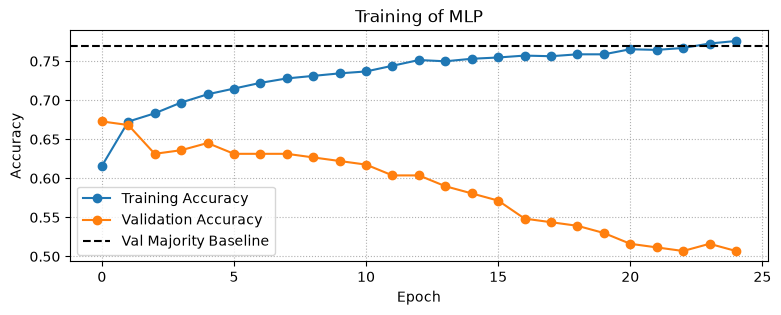

In [8]:
num_epochs = len(history_mlp.epoch)
plt.figure(figsize=(9, 3))
plt.plot(range(num_epochs), history_mlp.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(range(num_epochs), history_mlp.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.axhline(baseline_val_acc, color='k', linestyle='--', label='Val Majority Baseline')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training of MLP')
plt.grid(True, linestyle=':')
plt.legend()
plt.show()

In [9]:
# 2. Simple RNN for Binary Classification
model_srnn = Sequential([
    Input(shape=(n_features, 1)),
    SimpleRNN(32, return_sequences=True),
    SimpleRNN(24, return_sequences=True),
    SimpleRNN(16),
    Dense(1, activation='sigmoid')
])

model_srnn.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
history_srnn = model_srnn.fit(x=Xtrain_seq, y=ytrain, epochs=epochs, batch_size=32, validation_data=(Xval_seq, yval), verbose=1)

print(f'Simple RNN Validation Accuracy: {assess_acc(yval, model_srnn.predict(Xval_seq)):.4f}')

Epoch 1/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6255 - loss: 0.6536 - val_accuracy: 0.7097 - val_loss: 0.5943
Epoch 2/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6669 - loss: 0.6144 - val_accuracy: 0.6544 - val_loss: 0.6191
Epoch 3/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6816 - loss: 0.5975 - val_accuracy: 0.6406 - val_loss: 0.6379
Epoch 4/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7002 - loss: 0.5856 - val_accuracy: 0.6129 - val_loss: 0.6525
Epoch 5/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7067 - loss: 0.5758 - val_accuracy: 0.5899 - val_loss: 0.6622
Epoch 6/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7197 - loss: 0.5672 - val_accuracy: 0.5806 - val_loss: 0.6688
Epoch 7/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7303 - loss: 0.5597 - val_accuracy: 0.5853 - val_loss: 0.6743
Epoch 8/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7376 - loss: 0.5532 - val_accuracy: 0.5991 - val_loss

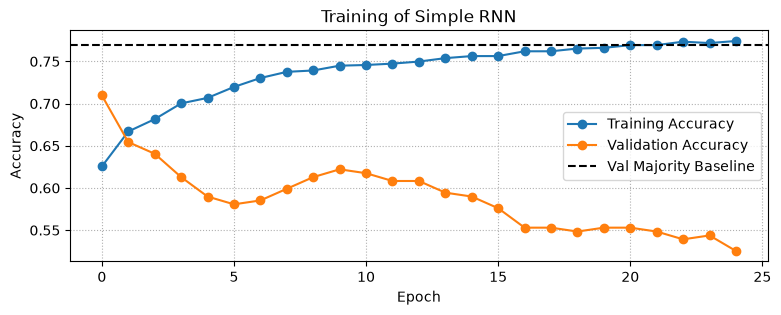

In [10]:
num_epochs = len(history_srnn.epoch)
plt.figure(figsize=(9, 3))
plt.plot(range(num_epochs), history_srnn.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(range(num_epochs), history_srnn.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.axhline(baseline_val_acc, color='k', linestyle='--', label='Val Majority Baseline')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training of Simple RNN')
plt.grid(True, linestyle=':')
plt.legend()
plt.show()

In [11]:
# 3. LSTM for Binary Classification
model_lstm = Sequential([
    Input(shape=(n_features, 1)),
    LSTM(16, return_sequences=True),
    LSTM(12, return_sequences=True),
    LSTM(8),
    Dense(1, activation='sigmoid')
])

model_lstm.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
history_lstm = model_lstm.fit(x=Xtrain_seq, y=ytrain, epochs=epochs, batch_size=32, validation_data=(Xval_seq, yval), verbose=1)

print(f'LSTM Validation Accuracy: {assess_acc(yval, model_lstm.predict(Xval_seq)):.4f}')

Epoch 1/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.5808 - loss: 0.6825 - val_accuracy: 0.7558 - val_loss: 0.6364
Epoch 2/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6190 - loss: 0.6685 - val_accuracy: 0.7558 - val_loss: 0.6103
Epoch 3/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6336 - loss: 0.6565 - val_accuracy: 0.7604 - val_loss: 0.5751
Epoch 4/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6401 - loss: 0.6469 - val_accuracy: 0.7512 - val_loss: 0.5622
Epoch 5/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6483 - loss: 0.6430 - val_accuracy: 0.7465 - val_loss: 0.5596
Epoch 6/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6474 - loss: 0.6408 - val_accuracy: 0.7558 - val_loss: 0.5568
Epoch 7/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6483 - loss: 0.6387 - val_accuracy: 0.7604 - val_loss: 0.5530
Epoch 8/25
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6474 - loss: 0.6367 - val_accuracy: 0.7558 - val_los

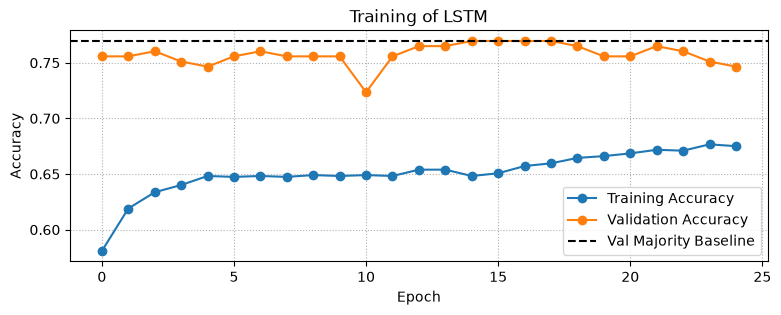

In [12]:
num_epochs = len(history_lstm.epoch)
plt.figure(figsize=(9, 3))
plt.plot(range(num_epochs), history_lstm.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(range(num_epochs), history_lstm.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.axhline(baseline_val_acc, color='k', linestyle='--', label='Val Majority Baseline')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training of LSTM')
plt.grid(True, linestyle=':')
plt.legend()
plt.show()

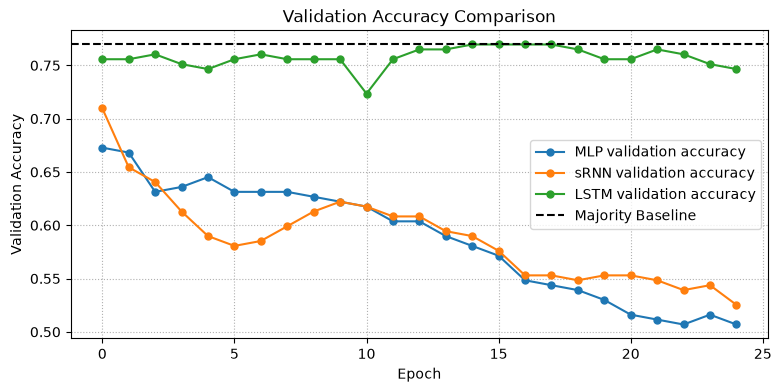

In [13]:
# Compare Validation Accuracy Curves Across Neural Network Models
plt.figure(figsize=(9, 4))
plt.plot(range(epochs), history_mlp.history['val_accuracy'], '.-', markersize=10, label='MLP validation accuracy')
plt.plot(range(epochs), history_srnn.history['val_accuracy'], '.-', markersize=10, label='sRNN validation accuracy')
plt.plot(range(epochs), history_lstm.history['val_accuracy'], '.-', markersize=10, label='LSTM validation accuracy')
plt.axhline(baseline_val_acc, color='k', linestyle='--', label='Majority Baseline')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy Comparison')
plt.grid(True, linestyle=':')
plt.legend()
plt.show()

In [14]:
# Final Validation Accuracy Summary
summary = pd.DataFrame({
    'Model': ['Majority Baseline', 'Logistic Regression', 'MLP', 'Simple RNN', 'LSTM'],
    'Validation Accuracy': [
        baseline_val_acc,
        assess_acc(yval, logreg.predict(Xval)),
        assess_acc(yval, model_mlp.predict(Xval)),
        assess_acc(yval, model_srnn.predict(Xval_seq)),
        assess_acc(yval, model_lstm.predict(Xval_seq))
    ]
})
print(summary.to_string(index=False))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              Model  Validation Accuracy
  Majority Baseline             0.769585
Logistic Regression             0.645161
                MLP             0.506912
         Simple RNN             0.525346
               LSTM             0.746544
